In [ ]:
# 让生成的表格显示在当前单元格的输出中，而不是弹出窗口
%matplotlib inline
import random
import torch
from d2l import torch as d2l

In [ ]:
# 定义生成数据的函数:w、b是真实的值
def synthetic_data(w, b, num_examples):
    """生成数据:y = Xw + b + 噪声"""
    # 特征矩阵X：num_examples行，len(w)列，每个元素服从均值为0，标准差为1的正态分布
    # 每行代表一个样本 每一列代表一个特征，例如X的形状为1000行2列
    X = torch.normal(0, 1, (num_examples, len(w)))  

    # matmul为矩阵乘法，计算无噪声预测值：y = Xw + b
    y = torch.matmul(X, w) + b  
    
    # 给y添加噪声，噪声服从均值为0，标准差为0.01的正态分布，同时y.shape保证了噪声的形状与y一致
    # 噪声很小，保证了基本符合线性规律，但是又不是完美的直线
    y += torch.normal(0, 0.01, y.shape)

    # y.reshape((-1, 1))中，-1表示行数自动计算，1表示列数固定为1
    # 保证了y的形状为(num_examples, 1)，即每个样本对应一个标签
    return X, y.reshape((-1, 1))

true_w = torch.tensor([2, -3.4])  # 真实的权重
true_b = 4.2  # 真实的偏置
features, labels = synthetic_data(true_w, true_b, 1000)

In [ ]:
# 打印特征矩阵X的第一行和标签y的第一行，方便查看数据格式
print('features:', features[0], '\nlabel:', labels[0])  

features: tensor([0.2463, 1.0541]) 
label: tensor([1.1082])


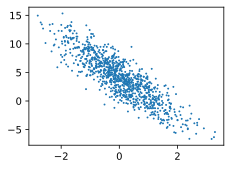

In [5]:
d2l.set_figsize()  # 设置图的尺寸
# 绘制散点图：这里取X的第二列(第一列也行)作为横坐标,y作为纵坐标,展示特征与标签的关系
# detach()方法把张量从计算图中分离出来，停止追踪梯度
# numpy()方法把张量转换为NumPy数组，方便绘图；1表示点的大小
d2l.plt.scatter(features[:, 1].detach().numpy(), 
                labels.detach().numpy(), 1);#加上分号可以避免输出返回值

In [ ]:
# 定义迭代器函数，用于批量取出数据
def data_iter(batch_size, features, labels):
    num_examples = len(features)  # 样本总数
    indices = list(range(num_examples))  # 生成样本索引列表
    random.shuffle(indices) # 随机打乱索引顺序

    # 如果batch_size=10, 那么i就是0, 10, 20, ..., 990
    for i in range(0, num_examples, batch_size):
        # 取出当前批次的索引，保证不超过样本总数
        batch_indices = torch.tensor(
            indices[i: min(i+batch_size, num_examples)]
        )
        # 通过索引取出当前批次的特征和标签，并使用yield返回一个生成器
        yield features[batch_indices], labels[batch_indices]
        
batch_size = 10

for X, y in data_iter(batch_size, features, labels):
    print(X, '\n', y)
    break  # 只查看第一个批次的特征和标签

tensor([[-0.2330, -0.6781],
        [ 0.4537, -1.1981],
        [ 0.8036,  1.0210],
        [-0.5515,  1.1254],
        [-0.0239, -0.0183],
        [-0.0612,  0.4852],
        [ 0.2871, -0.2669],
        [-0.2132,  0.0270],
        [ 1.5961,  0.3554],
        [ 0.6942,  0.2629]]) 
 tensor([[ 6.0411],
        [ 9.1882],
        [ 2.3151],
        [-0.7366],
        [ 4.2167],
        [ 2.4368],
        [ 5.6825],
        [ 3.6795],
        [ 6.1684],
        [ 4.6973]])


In [21]:
# 初始化模型参数
w = torch.normal(0, 0.01, size=(2, 1), requires_grad=True)  # 权重初始化为均值为0，标准差为0.01的正态分布
b = torch.zeros(1, requires_grad=True)  # 偏置初始化为0

In [9]:
# 定义线性回归模型
def linreg(X, w, b):
    return torch.matmul(X, w) + b  # 矩阵乘法计算预测值

In [10]:
# 定义损失函数: y_hat是预测值，y是真实值
def squared_loss(y_hat, y):
    """均方损失"""
    return (y_hat - y.reshape(y_hat.shape)) ** 2 / 2  # 均方误差损失函数

In [11]:
# 定义参数更新算法：params是要更新的模型参数列表，lr是学习率，batch_size是批量大小
def sgd(params, lr, batch_size):
    """小批量随机梯度下降"""
    with torch.no_grad():   # 这一块代码的计算不加入计算图，不用计算梯度
        for param in params:    # 对w和b进行更新
            param -= lr * param.grad / batch_size  # 更新参数，之前梯度是累加的，所以要除以batch_size
            param.grad.zero_()  # 清空梯度，避免累加


In [22]:
# 训练模型
"""
每次训练分为如下5步：
1、准备数据：用data_iter函数生成小批量数据
2、前向传播：把X输入模型，得到预测值y_hat = X@w + b
3、计算损失：用均方误差损失函数squared_loss计算y_hat和y之间的误差loss
4、反向传播：调用loss.backward()计算梯度
5、更新参数：调用sgd函数更新模型参数w和b，然后清零梯度，进行下一轮迭代
"""
lr = 0.02  # 学习率
num_epochs = 3  # 训练轮数
net = linreg  # 模型
loss = squared_loss  # 损失函数

for epoch in range(num_epochs):
    for X, y in data_iter(batch_size, features, labels):
        l = loss(net(X, w, b), y)  # 计算小批量损失
        l.sum().backward()  # 反向传播计算梯度
        sgd([w, b], lr, batch_size)  # 使用小批量随机梯度下降更新参数
    # 更新完参数后，查看在所有样本上的损失，并打印每轮的平均损失
    # 这一步只是检测模型的整体训练情况，不参与梯度计算，所以用torch.no_grad()包裹
    with torch.no_grad():  
        train_l = loss(net(features, w, b), labels)  # 计算所有样本的损失
        print(f'epoch {epoch + 1}, loss {float(train_l.mean()):f}')  # 打印每轮的平均损失


epoch 1, loss 0.344109
epoch 2, loss 0.007616
epoch 3, loss 0.000218


In [23]:
print(f'w的估计误差: {true_w - w.reshape(true_w.shape)}')  # 打印权重的估计误差
print(f'b的估计误差: {true_b - b}')  # 打印偏置的估计误差


w的估计误差: tensor([ 0.0087, -0.0112], grad_fn=<SubBackward0>)
b的估计误差: tensor([0.0133], grad_fn=<RsubBackward1>)
